# A tour of MEDT

**Multipartite Entanglement Detection Toolkit**

[Entanglement](https://en.wikipedia.org/wiki/Quantum_entanglement) shared by three or more parties is a resource for quantum networks, sensing and error correction, and it is also a fingerprint of quantum phases of matter. But given a noisy, mixed state, it is hard to tell whether it is entangled at all: the set of unentangled (separable) states has no simple description, and deciding membership is NP-hard in general ([Gurvits 2003](https://arxiv.org/abs/quant-ph/0303055)). In practice one attacks the question from both sides:

- **certificates of entanglement**, such as entanglement witnesses and [semidefinite programs](https://en.wikipedia.org/wiki/Semidefinite_programming) built on the partial transpose, which prove that a state *is* entangled, and
- **certificates of separability**, such as an explicit decomposition into unentangled pieces, which prove that it *is not*.

When the two sides meet, the question is settled. For a friendly introduction to the subject, see the reviews by [Gühne and Tóth](https://arxiv.org/abs/0811.2803) and by [the Horodeckis](https://arxiv.org/abs/quant-ph/0702225).

This notebook starts with a two-party warm-up and then runs four light multipartite examples, each taking seconds to a minute on a laptop:

1. Warm-up: entanglement between two parties, measured by the negativity.
2. Is a noisy three-qubit GHZ state genuinely multipartite entangled? We certify the answer from both sides.
3. How much entanglement is there? Upper and lower bounds on an entanglement measure.
4. Entanglement at a quantum phase transition, in the transverse-field Ising chain.
5. Network entanglement: entanglement that cannot be built from pairwise sources.

An appendix shows the helper behind *entanglement microscopy*: pulling the reduced state of a few sites out of a large many-body state, so that any of the methods above can be applied to it.

Each section links to the paper behind the method; the [README](../README.md) has the full reference list.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from scipy import sparse

import medt
from medt.states import ghz, ket_to_dm, w, white_noise

plt.rcParams.update({
    "figure.figsize": (6, 3.4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
})
BLUE = "#2a78d6"
MUTED = "#8a8984"
warnings.filterwarnings("ignore", message="Solution may be inaccurate")  # SCS accuracy notes near GMN = 0


## 1. Warm-up: entanglement between two parties

Start with two qubits, $A$ and $B$. A pure state is entangled when it cannot be written as a product $|\phi\rangle_A \otimes |\chi\rangle_B$, like the Bell state $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}$. For mixed states the question becomes whether $\rho$ is a mixture of product states.

A simple and powerful test is the [partial transpose](https://en.wikipedia.org/wiki/Peres%E2%80%93Horodecki_criterion): transpose only the indices of $B$. For a separable state the result is still a valid density matrix, so a negative eigenvalue proves entanglement ([Peres 1996](https://arxiv.org/abs/quant-ph/9604005)). For two qubits, or a qubit and a qutrit, the converse also holds, so this test is exact ([Horodecki, Horodecki and Horodecki 1996](https://arxiv.org/abs/quant-ph/9605038)). The **negativity**, the sum of the magnitudes of those negative eigenvalues, turns the test into a computable entanglement measure ([Vidal and Werner 2002](https://arxiv.org/abs/quant-ph/0102117)).

Mix the Bell state with white noise, $\rho(p) = (1-p)\,|\Phi^+\rangle\langle\Phi^+| + p\,\mathbb{1}/4$. This is the two-qubit [Werner state](https://doi.org/10.1103/PhysRevA.40.4277) (Werner 1989, which predates arXiv). Its partial transpose has one eigenvalue $p/4 - (1-p)/2$ that can be negative, so the negativity is $\max(0, (2-3p)/4)$, and the state is entangled exactly when $p < 2/3$. This was the example Peres used to introduce the criterion ([Peres 1996](https://arxiv.org/abs/quant-ph/9604005)).

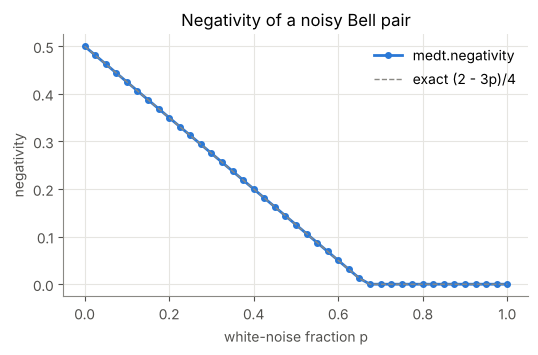

In [2]:
rho_bell = ket_to_dm(ghz(2))  # (|00> + |11>)/sqrt(2)
ps_bell = np.linspace(0, 1, 41)
neg_values = [medt.negativity(white_noise(rho_bell, p), [0], [2, 2]) for p in ps_bell]

fig, ax = plt.subplots()
ax.plot(ps_bell, neg_values, color=BLUE, lw=2, marker="o", ms=4, label="medt.negativity")
ax.plot(ps_bell, np.maximum(0, (2 - 3 * ps_bell) / 4), color=MUTED, ls="--", lw=1, label="exact (2 - 3p)/4")
ax.set(xlabel="white-noise fraction p", ylabel="negativity", title="Negativity of a noisy Bell pair")
ax.legend(frameon=False)
plt.show()


With three or more parties, looking at pairs is not enough. Below, `keep_systems` traces out qubit $C$ (see the appendix) and we compute the negativity between $A$ and $B$. In the GHZ state the pair $AB$ is not entangled at all, although $A$ is maximally entangled with the pair $BC$. In the W state the pairs are entangled. Entanglement shared among all three parties needs its own tools, which the rest of this notebook is about.

In [3]:
for name, psi in [("GHZ", ghz(3)), ("W", w(3))]:
    rho3 = ket_to_dm(psi)
    pair = medt.keep_systems(psi, [0, 1], [2, 2, 2])
    print(f"{name}: negativity A|BC = {medt.negativity(rho3, [0], [2, 2, 2]):.4f}, "
          f"negativity A|B after tracing out C = {abs(medt.negativity(pair, [0], [2, 2])):.4f}")


GHZ: negativity A|BC = 0.5000, negativity A|B after tracing out C = 0.0000
W: negativity A|BC = 0.4714, negativity A|B after tracing out C = 0.2060


## 2. Is a noisy GHZ state genuinely multipartite entangled?

Take the three-qubit [GHZ state](https://en.wikipedia.org/wiki/Greenberger%E2%80%93Horne%E2%80%93Zeilinger_state) $|\mathrm{GHZ}\rangle = (|000\rangle + |111\rangle)/\sqrt{2}$ and mix it with white noise, which models a noisy preparation:

$$\rho(p) = (1-p)\,|\mathrm{GHZ}\rangle\langle\mathrm{GHZ}| + p\,\frac{\mathbb{1}}{8}.$$

Split the three qubits $A, B, C$ into two groups, for example $A|BC$. A state is *biseparable* if it can be written as a probabilistic mixture of states that are each unentangled across one such split (the split may differ from term to term). Biseparable states can be made by entangling only some of the parties at a time. A state that is not biseparable has **genuine multipartite entanglement** (GME): all three qubits are entangled together.

The **genuine multiparticle negativity** (GMN) of [Jungnitsch, Moroder and Gühne (2011)](https://arxiv.org/abs/1010.6049) is a semidefinite program that tests GME using the [partial transpose](https://en.wikipedia.org/wiki/Peres%E2%80%93Horodecki_criterion); GMN $> 0$ certifies GME.

For this state the exact answer is known: it is GME exactly when $p < 4/7$, i.e. when its overlap with the GHZ state, $(1-p) + p/8$, exceeds $1/2$ ([Gühne and Seevinck 2010](https://arxiv.org/abs/0905.1349)). Let's see GMN find this threshold.

33 SDPs in 1.8 s


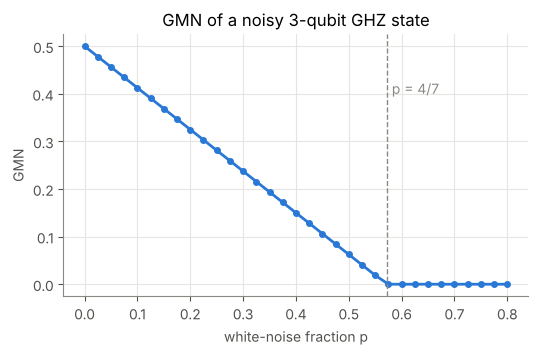

In [4]:
ps = np.linspace(0, 0.8, 33)
rho_ghz = ket_to_dm(ghz(3))
t0 = time.time()
gmn_values = [medt.gmn(white_noise(rho_ghz, p)) for p in ps]
print(f"{len(ps)} SDPs in {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(ps, gmn_values, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(4 / 7, color=MUTED, ls="--", lw=1)
ax.text(4 / 7 + 0.01, 0.4, "p = 4/7", color=MUTED)
ax.set(xlabel="white-noise fraction p", ylabel="GMN", title="GMN of a noisy 3-qubit GHZ state")
plt.show()


GMN is positive up to $p = 4/7$ and vanishes beyond it. A vanishing GMN alone does not prove that the state is biseparable, since GMN is only a sufficient test for entanglement. The **adaptive polytope** method of [Ohst, Yu, Gühne and Sarbicki (2024)](https://arxiv.org/abs/2210.10054) provides the other side: it searches for an explicit biseparable decomposition, and reports a robustness $t \ge 1$ when it finds one.

In [5]:
for p in (0.5, 0.65):
    res = medt.polytope_biseparable(white_noise(rho_ghz, p), [2, 2, 2], seed=0)
    print(f"p = {p}: biseparable certified = {res.certified}  (robustness t = {res.robustness:.3f})")


p = 0.5: biseparable certified = False  (robustness t = 0.853)


p = 0.65: biseparable certified = True  (robustness t = 1.145)


At $p = 0.65$ the state is certified biseparable, and at $p = 0.5$ GMN certified it GME. Together the two methods pin down the threshold.

## 3. How much entanglement is there?

Beyond a yes/no answer, one often wants to *quantify* entanglement. The **genuine multipartite concurrence** (GMC) of [Ma *et al.* (2011)](https://arxiv.org/abs/1101.2001) is one such measure. For pure states it has a closed form; for mixed states it is a *convex roof*, the minimum average over all ways of writing $\rho$ as a mixture of pure states. That minimum is hard to compute exactly, so MEDT brackets it:

- `gmc_lower_bound`: a lower bound from [Ma *et al.* (2011)](https://arxiv.org/abs/1101.2001), optimized over product states.
- `gmc_convex_roof`: an upper bound, found by gradient descent over decompositions, as in [Lyu *et al.* (2025)](https://arxiv.org/abs/2412.12533). Every decomposition of $\rho$ into $k$ pure states corresponds to a $k \times r$ matrix with orthonormal columns ($r$ is the rank of $\rho$). These matrices form a curved space, the [Stiefel manifold](https://en.wikipedia.org/wiki/Stiefel_manifold), so the descent has to stay on it; this is *Riemannian* gradient descent, introduced gently in [Boumal's free textbook](https://sma.epfl.ch/~nboumal/book/IntroOptimManifolds_Boumal_2022.pdf).

Here is a W state $(|001\rangle + |010\rangle + |100\rangle)/\sqrt{3}$ with 10% white noise.

In [6]:
rho_w = white_noise(ket_to_dm(w(3)), 0.1)
lo = medt.gmc_lower_bound(rho_w, [2, 2, 2], n_starts=5, seed=0)
hi = medt.gmc_convex_roof(rho_w, [2, 2, 2], seed=0)
print(f"noisy W state: {lo:.4f} <= GMC <= {hi:.4f}")
print(f"pure W state:  GMC = {medt.gmc_pure(w(3)):.4f}")


noisy W state: 0.4709 <= GMC <= 0.7042
pure W state:  GMC = 0.9428


## 4. Entanglement at a quantum phase transition

The [transverse-field Ising chain](https://en.wikipedia.org/wiki/Transverse-field_Ising_model) $H = -\sum_i (X_i X_{i+1} + h Z_i)$ is the textbook example of a [quantum phase transition](https://en.wikipedia.org/wiki/Quantum_phase_transition): a ferromagnet for $h < 1$, a paramagnet for $h > 1$, and critical at $h = 1$.

The model maps to free fermions, so the reduced density matrix of any few spins of the *infinite* chain can be computed exactly, without diagonalizing a large Hamiltonian ([Fagotti and Essler 2013](https://arxiv.org/abs/1302.6944)). `medt.tfim.tfim_rdm` does this at zero or finite temperature. We use it twice: first for two-party entanglement between separated blocks of spins, then for genuine three-party entanglement.

### Entanglement versus distance

Take two blocks of $\ell$ neighbouring spins each, separated by a gap of $d$ spins, in the ground state at the critical point $h = 1$. How does their entanglement, measured by the logarithmic negativity $\log_2 \|\rho^{T_A}\|_1$, fall off as the gap grows? Correlations at a critical point decay slowly, as a power of the distance, but the negativity does something more dramatic: it drops to exactly zero beyond a finite gap, a "sudden death". The death distance grows quickly with the block size, as found by [Javanmard, Trapin, Bera, Bardarson and Heyl (2018)](https://arxiv.org/abs/1805.06935). [Parez and Witczak-Krempa (2023)](https://arxiv.org/abs/2310.15273) show more generally that in critical ground states the negativity between distant regions decays faster than any power of the distance.

This is a good place to experiment: change the block sizes, the gaps or the field $h$, or pass `beta=` to look at finite temperature. Blocks of up to three spins take seconds.

blocks of 1: entangled up to gap d = 1, zero beyond


blocks of 2: entangled up to gap d = 2, zero beyond


blocks of 3: entangled up to gap d = 9, zero beyond


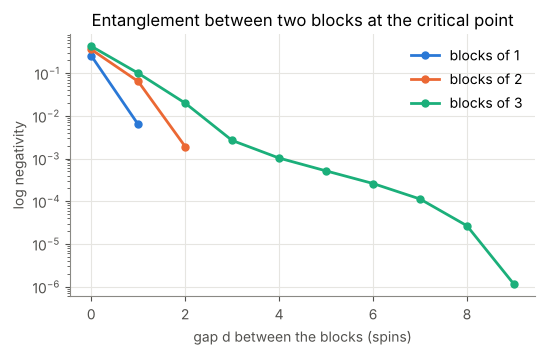

In [7]:
gaps = np.arange(0, 13)
colors = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
fig, ax = plt.subplots()
for ell in (1, 2, 3):
    logneg = []
    for d in gaps:
        sites = list(range(ell)) + list(range(ell + d, 2 * ell + d))  # block A, gap of d spins, block B
        rho = medt.tfim.tfim_rdm(1.0, sites)
        logneg.append(medt.log_negativity(rho, range(ell), [2] * (2 * ell)))
    logneg = np.array(logneg)
    alive = logneg > 1e-10
    ax.semilogy(gaps[alive], logneg[alive], color=colors[ell], lw=2, marker="o", ms=5, label=f"blocks of {ell}")
    print(f"blocks of {ell}: entangled up to gap d = {gaps[alive].max()}, zero beyond")
ax.set(xlabel="gap d between the blocks (spins)", ylabel="log negativity",
       title="Entanglement between two blocks at the critical point")
ax.legend(frameon=False)
plt.show()


### Genuine three-party entanglement across the transition

Now look at three neighbouring spins and compute their GMN as the field $h$ varies, across the phase transition.

30 reduced states + SDPs in 2.9 s


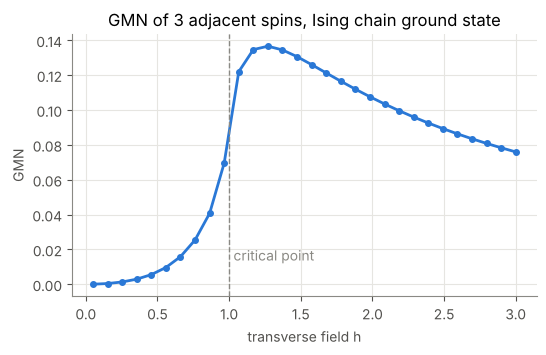

In [8]:
hs = np.linspace(0.05, 3.0, 30)
t0 = time.time()
gmn_tfim = [medt.gmn(medt.tfim.tfim_rdm(h, [0, 1, 2])) for h in hs]
print(f"{len(hs)} reduced states + SDPs in {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
ax.plot(hs, gmn_tfim, color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(1.0, color=MUTED, ls="--", lw=1)
ax.text(1.03, max(gmn_tfim) * 0.1, "critical point", color=MUTED)
ax.set(xlabel="transverse field h", ylabel="GMN", title="GMN of 3 adjacent spins, Ising chain ground state")
plt.show()


The GMN rises sharply near the critical point, peaks just above it, and decays slowly in the paramagnetic phase. At small $h$ the three spins are close to a classical mixture of "all up" and "all down", so GME vanishes.

Studies of the same chain with other GME criteria see the same picture, with a derivative that diverges at the critical point: [Wang, Song, Lyu, Witczak-Krempa and Meng (2025)](https://arxiv.org/abs/2402.14916) and [Lyu, Song, Wang, Meng and Witczak-Krempa (2025)](https://arxiv.org/abs/2412.12533).

### Finite temperature

So far the chain sat in its ground state. A real system is never at exactly zero temperature: at temperature $T$ it is in the Gibbs (thermal) state $\rho = e^{-H/T}/Z$, where $Z$ normalizes the trace and we set Boltzmann's constant to one. Passing `beta=1/T` to `medt.tfim.tfim_rdm(h, sites, beta=1/T)` returns the exact reduced density matrix of the infinite chain in this thermal state. It again comes from the free-fermion mapping, so there are no finite-size effects.

Heating the chain mixes excited states into the ground state, and this classical randomness washes out quantum correlations. We therefore expect the GMN of three neighbouring spins to shrink as $T$ grows and to vanish exactly at some finite temperature, a "sudden death" of genuine multipartite entanglement rather than a slow decay towards zero. Related temperature scans appear in [Wang, Song, Lyu, Witczak-Krempa and Meng (2025)](https://arxiv.org/abs/2402.14916), Fig. 3, for bipartite entanglement, and in [Lyu, Lauand and Witczak-Krempa (2026)](https://arxiv.org/abs/2512.11118) for network entanglement. Below we track the GMN versus $T$ for a field in the ferromagnetic phase, at the critical point, and at two fields in the paramagnetic phase.

180 thermal states + SDPs in 16.3 s
h = 0.5: GMN(T -> 0) = 0.0071, GMN vanishes for T >= 0.42
h = 1.0: GMN(T -> 0) = 0.0913, GMN vanishes for T >= 0.76
h = 1.5: GMN(T -> 0) = 0.1295, GMN vanishes for T >= 1.06
h = 3.0: GMN(T -> 0) = 0.0760, GMN vanishes for T >= 1.85


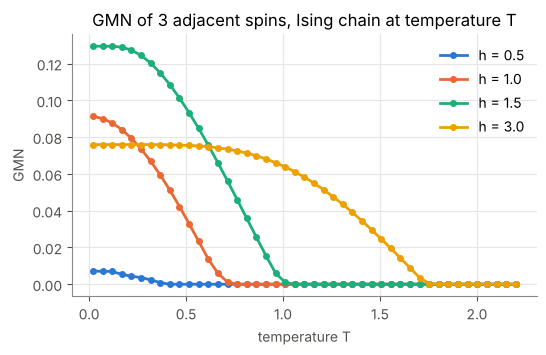

In [9]:
temps = np.linspace(0.02, 2.2, 45)
fields = (0.5, 1.0, 1.5, 3.0)
t0 = time.time()
gmn_thermal = {
    h: np.array([max(medt.gmn(medt.tfim.tfim_rdm(h, [0, 1, 2], beta=1 / T)), 0.0) for T in temps]) for h in fields
}
print(f"{len(fields) * len(temps)} thermal states + SDPs in {time.time() - t0:.1f} s")

fig, ax = plt.subplots()
for h, color in zip(fields, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=True):
    ax.plot(temps, gmn_thermal[h], color=color, lw=2, marker="o", ms=4, label=f"h = {h}")
    dead = temps[gmn_thermal[h] < 1e-6]
    if dead.size:
        print(f"h = {h}: GMN(T -> 0) = {gmn_thermal[h][0]:.4f}, GMN vanishes for T >= {dead[0]:.2f}")
    else:
        print(f"h = {h}: GMN still positive at T = {temps[-1]:.2f}")
ax.set(xlabel="temperature T", ylabel="GMN", title="GMN of 3 adjacent spins, Ising chain at temperature T")
ax.legend(frameon=False)
plt.show()

For every field the GMN reaches exactly zero at a finite temperature, so the sudden death is real. The death temperature is about $T \approx 0.4$ for $h = 0.5$, $0.8$ at the critical point, $1.05$ for $h = 1.5$ and $1.8$ for $h = 3$ (the grid spacing is $0.05$, so these are rough values).

Note that a larger ground-state GMN does not mean a higher death temperature. Deep in the paramagnetic phase the ground state approaches the product state $|{\uparrow\uparrow\uparrow}\rangle$, so its GMN shrinks (from $0.13$ at $h = 1.5$ to $0.076$ at $h = 3$), yet it survives to higher temperature, because the energy gap $2|h-1|$ grows with $h$ and keeps the chain close to its ground state. Measured in units of the field, $T/h$, the death temperature does decrease as $h$ grows. The bipartite negativity of two neighbouring spins behaves the same way: it dies at a somewhat higher temperature than the GMN, and that temperature also grows with $h$. The shape of the curves differs too: away from the critical point the GMN stays almost flat at low $T$, until $T$ becomes comparable to the gap, while at $h = 1$ the gap closes and the GMN decreases as soon as the temperature is switched on.

## 5. Network entanglement

Many quantum networks distribute entanglement through *two-party* sources, such as photon pairs, and then let each party act locally. Some multipartite entangled states can be made this way and some cannot. States that cannot have *genuine network multipartite entanglement* (GNME), a stronger property than GME ([Navascués *et al.* 2020](https://arxiv.org/abs/2002.02773)).

The **ring inflation** test certifies GNME. Imagine that the state did come from a network; then copies of its sources could be rewired into a larger ring, and the resulting states would have to exist. A semidefinite program checks whether they can. The test returns the largest $t$ for which the noisier state $t\rho + (1-t)\mathbb{1}/D$ passes, so $t < 1$ certifies GNME. The **Gilbert criterion** gives the other side: a noise level above which the state *is* a network state. Both follow [Lyu, Lauand and Witczak-Krempa (2026)](https://arxiv.org/abs/2512.11118).

In [10]:
for name, psi, p in [("GHZ", ghz(3), 0.2), ("GHZ", ghz(3), 0.45), ("W", w(3), 0.25)]:
    rho = white_noise(ket_to_dm(psi), p)
    t = medt.ring_inflation_robustness(rho, [2, 2, 2])
    verdict = "GNME certified" if t < 1 else "not certified by level-2 inflation"
    print(f"{name} with p = {p}: t_max = {t:.3f} -> {verdict}")


GHZ with p = 0.2: t_max = 0.790 -> GNME certified


GHZ with p = 0.45: t_max = 1.149 -> not certified by level-2 inflation


W with p = 0.25: t_max = 0.933 -> GNME certified


The noisy GHZ state at $p = 0.45$ is still GME (since $0.45 < 4/7$), but level-2 inflation no longer certifies network entanglement. Passing `level=3` gives tighter bounds and reproduces the thresholds $p = 0.3878$ (GHZ) and $p = 0.3486$ (W) of [Lyu, Lauand and Witczak-Krempa (2026)](https://arxiv.org/abs/2512.11118), in a few minutes each.

## Appendix: entanglement microscopy

In [entanglement microscopy](https://arxiv.org/abs/2402.14916) (Wang, Song, Lyu, Witczak-Krempa and Meng, Nat. Commun. 2025), one looks at a quantum many-body system through a microscope: zoom in on a few sites, extract their reduced state, and examine its entanglement. MEDT provides the extraction step as a helper. Once you have the reduced state, every method above applies.

Many-body calculations usually produce one large pure state $|\psi\rangle$ of $N$ spins, for example a ground state. The [reduced density matrix](https://en.wikipedia.org/wiki/Partial_trace) of a few spins is obtained by tracing out the rest. Forming the full $2^N \times 2^N$ density matrix first would be wasteful (for $N = 20$ that is a trillion entries), so MEDT works directly from $|\psi\rangle$:

- `keep_systems(state, keep, dims)` returns the reduced state of the subsystems in `keep`, in the order requested.
- `partial_trace(state, trace_out, dims)` traces out the listed subsystems.

Both accept kets or density matrices, dense or sparse, with any local dimensions. For fermions, `medt.fermions.fermionic_keep_systems` does the same, keeping track of the signs that appear when fermionic modes are reordered.

To get a large state, `medt.tfim.tfim_ground_state` finds the ground state of a ring of 20 Ising spins at the critical point with the [Lanczos algorithm](https://en.wikipedia.org/wiki/Lanczos_algorithm), a vector of $2^{20} \approx 10^6$ amplitudes. A finite periodic chain is again solvable by free fermions, which gives an exact energy to check against.

In [11]:
L, h = 20, 1.0
t0 = time.time()
energy, psi = medt.tfim.tfim_ground_state(L, h)
print(f"Lanczos, L = {L}: E0 = {energy:.8f} in {time.time() - t0:.1f} s")
k = np.pi * (2 * np.arange(L) + 1) / L
print(f"free-fermion exact:  E0 = {-np.sum(np.sqrt(1 + h**2 - 2 * h * np.cos(k))):.8f}")

dims = [2] * L
t0 = time.time()
rho_adj = medt.keep_systems(psi, [0, 1, 2], dims)        # three adjacent spins
rho_far = medt.keep_systems(psi, [10, 0, 5], dims)       # spaced spins, ordered as (10, 0, 5)
rho_pt = medt.partial_trace(psi, range(3, L), dims)      # same as rho_adj, by tracing out the rest
print(f"three reduced states in {time.time() - t0:.2f} s")
print("keep_systems agrees with partial_trace:", np.allclose(rho_adj, rho_pt))

print(f"GMN, 3 adjacent spins, L = 20 ring:     {medt.gmn(rho_adj):.5f}")
print(f"GMN, 3 adjacent spins, infinite chain:  {medt.gmn(medt.tfim.tfim_rdm(h, [0, 1, 2])):.5f}")
print(f"GMN, spins (10, 0, 5):                  {max(medt.gmn(rho_far), 0.0):.5f}")


Lanczos, L = 20: E0 = -25.49098969 in 11.6 s
free-fermion exact:  E0 = -25.49098969
three reduced states in 0.01 s
keep_systems agrees with partial_trace: True
GMN, 3 adjacent spins, L = 20 ring:     0.09405


GMN, 3 adjacent spins, infinite chain:  0.09140
GMN, spins (10, 0, 5):                  0.00000


Through this microscope, three neighbouring spins on a ring of 20 sites already look almost like those of the infinite chain in section 4, while spins five sites apart share no genuine three-party entanglement.

Sparse states are handled without ever building a dense vector. Here are two qubits of a 24-qubit W state, which has only 24 nonzero amplitudes out of $2^{24} \approx 1.7 \times 10^7$:

In [12]:
n = 24
w24 = sparse.coo_array((np.full(n, n**-0.5), (1 << np.arange(n),)), shape=(2**n,))
rho_pair = medt.keep_systems(w24, [3, 17], [2] * n)
print(np.round(rho_pair.real, 4))
print("negativity between the two qubits:", round(medt.negativity(rho_pair, [0], [2, 2]), 5))


[[0.9167 0.     0.     0.    ]
 [0.     0.0417 0.0417 0.    ]
 [0.     0.0417 0.0417 0.    ]
 [0.     0.     0.     0.    ]]
negativity between the two qubits: 0.00189


## Outlook: the bigger picture

Every example above asks the same kind of question. Entanglement is defined relative to a **free set**: the separable states for bipartite entanglement, and the biseparable states for genuine multipartite entanglement. Both sets are convex, since mixing free states gives a free state. Detecting entanglement means deciding whether a given $\rho$ lies *outside* the free set, and quantifying it means measuring *how far* outside it lies, as the robustness $t$ and the GMN do.

The same picture describes other quantum resources. In [quantum magic](https://arxiv.org/abs/1307.7171), the resource behind universal fault-tolerant quantum computing, the free set is the set of stabilizer states. Coherence, asymmetry and many others fit the same mould, reviewed in [Chitambar and Gour (2019)](https://arxiv.org/abs/1806.06107).

So the core problem is **membership in a convex set**, and for entanglement it is NP-hard in general ([Gurvits 2003](https://arxiv.org/abs/quant-ph/0303055)). The methods in this toolkit are all approximate solutions to it, approaching the free set from outside or from inside:

- **Semidefinite programs** replace the free set with a slightly larger one that is easy to describe, such as PPT states or PPT mixtures (negativity, GMN, ring inflation). If $\rho$ lies outside the larger set, it is certainly entangled.
- **Inner approximations**, such as the adaptive polytopes, build a slightly smaller set from explicit free states. If $\rho$ lies inside it, it is certainly free.
- **Nonlinear optimization**, such as the gradient descent over decompositions for the convex roof, searches directly for the best decomposition.
- **First-order convex methods** in the [Frank–Wolfe](https://en.wikipedia.org/wiki/Frank%E2%80%93Wolfe_algorithm) family, such as Gilbert's algorithm behind the Gilbert criterion, only need to optimize a linear function over the free set at each step, which makes them practical for large problems ([Brierley, Navascués and Vértesi 2016](https://arxiv.org/abs/1609.05011); [Shang and Gühne 2018](https://arxiv.org/abs/1707.02958)).

The same strategies carry over to other resources once the free set is swapped.

## Where to go next

- The [README](../README.md) lists every method with a usage snippet and its references.
- The `tests/` folder reproduces published numbers: GMN in the Kitaev honeycomb model, GMN and Rains entanglement in the Ising chain, and network-entanglement thresholds.
- All semidefinite programs go through [CVXPY](https://www.cvxpy.org), so you can pass `solver="MOSEK"` or any other installed solver.